# CIC-IDS2017 — Reconnaissance / PortScan Dataset Preparation
## SIH 2026 - Problem Statement 26145: AI-Based Detection of Cyber Threats in Unidirectional IP Traffic

---

### Executive Objective
This notebook implements **Step 11** of the SIH Problem Statement 26145 pipeline: preparing a clean, leakage-aware, binary **Reconnaissance / Port Scanning** detection dataset from the preprocessed **CIC-IDS2017** benchmark (`data/processed/CIC_IDS2017_cleaned.csv`).

The primary detection objective for this phase is:
- **Malicious Positive Class ($y = 1$)**: `PortScan` (`TrafficClass = "PortScan"`, `BinaryLabel = 1`)
- **Normal Negative Class ($y = 0$)**: `BENIGN` (`TrafficClass = "Normal"`, `BinaryLabel = 0`)

---

### Threat-Mapping & Reconnaissance Context
Reconnaissance is the initial discovery phase of the Cyber Kill Chain. Attackers perform active network port scanning (e.g. via `Nmap`, `Masscan`, or custom probing scripts) to map live hosts, identify listening services, and discover open TCP/UDP ports before launching targeted exploitation.

In unidirectional and bidirectional flow telemetry, port scanning manifests as:
1. **High Flow Velocity & Short Durations**: Rapid sequences of micro-flows probing multiple destination ports with minimal session duration.
2. **Asymmetrical Byte & Packet Profiles**: Single-packet or low-packet probes with little to no backward response payload.
3. **Characteristic TCP Flag Configurations**: High prevalence of solitary `SYN` flags, `RST-ACK` responses, or `FIN`/`NULL`/`XMAS` scan signatures designed to evade stateful firewalls.
4. **Broad Destination Port Diversity**: Flows targeting varied service ports (e.g. 21, 22, 80, 443, 445, 3389, 8080) with uniform packet headers.

---

### Isolation Forest Anomaly Detection Philosophy (Next Phase)
In the upcoming modeling phase (Step 12), we employ **Isolation Forest** as the primary anomaly detector:
- **Unsupervised Normal Baseline Calibration**: Isolation Forest recursively partitions feature space using random orthogonal splits. Sparse anomalous flows (such as port scans) require fewer splits to isolate and appear near the tree root.
- **Normal Training Baseline**: The training partition consists **exclusively of clean Normal/BENIGN traffic ($y = 0$)**.
- **Zero Attack Contamination**: PortScan attack traffic is strictly excluded from model fitting and used exclusively during unseen evaluation.

---

### Strict Threat Separation & Data-Leakage Protocol
1. **Attack Family Separation**: All other attack labels (`DDoS`, `DoS Hulk`, `DoS GoldenEye`, `DoS slowloris`, `DoS Slowhttptest`, `FTP-Patator`, `SSH-Patator`, `Bot`, `Web Attacks`, `Infiltration`, `Heartbleed`) are strictly excluded from the primary PortScan dataset and documented in a dedicated Threat Coverage Summary (`portscan_coverage_summary.csv`).
2. **Class-Wise Temporal Holdout**: Because wall-clock timestamps were stripped by the benchmark authors, we prepare a deterministic 70/30 class-wise temporal holdout based on the retained row sequence:
   - PortScan: First 70% ($N = 63,573$) → historical attack portion; Last 30% ($N = 27,246$) → evaluation attack portion.
   - BENIGN: First 70% ($N = 1,467,538$) → normal training baseline; Last 30% ($N = 628,946$) → evaluation normal portion.
3. **Memory Management (8 GB RAM)**: Data extraction and transformation are executed in streaming chunks of 200,000 rows.
4. **Source Data Immutability**: The source dataset (`data/processed/CIC_IDS2017_cleaned.csv`) remains strictly unmodified.

### 1. Import Libraries & Setup Display Options
Import required scientific, memory management, and visualization libraries.

In [1]:
import os
import sys
import gc
import json
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
if hasattr(sys.stdout, 'reconfigure'):
    try:
        sys.stdout.reconfigure(encoding='utf-8')
    except Exception:
        pass

# Display configurations
pd.set_option('display.max_columns', 35)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

print(f"NumPy version:  {np.__version__}")
print(f"Pandas version: {pd.__version__}")

NumPy version:  2.5.3
Pandas version: 3.0.6


### 2. Verify Source Dataset (`CIC_IDS2017_cleaned.csv`)
Verify file existence, file size, column schema, and inspect a 5-row sample.

In [2]:
# Resolve project root dynamically
if Path('data/processed').exists():
    project_root = Path.cwd().resolve()
elif Path('../data/processed').exists():
    project_root = Path.cwd().parent.resolve()
else:
    project_root = Path.cwd().resolve()

raw_path = project_root / 'data' / 'processed' / 'CIC_IDS2017_cleaned.csv'
out_dir = project_root / 'data' / 'processed' / 'CIC_IDS2017'
out_dir.mkdir(parents=True, exist_ok=True)

if not raw_path.exists():
    raise FileNotFoundError(f"Input dataset not found at {raw_path}")

raw_size_mb = raw_path.stat().st_size / (1024 * 1024)
print(f"Input Dataset Path: {raw_path.name}")
print(f"Dataset File Size:  {raw_size_mb:.2f} MB")

# Read small sample to detect available schema
sample_df = pd.read_csv(raw_path, nrows=5)
print(f"Sample Dimensions:  {sample_df.shape[0]} rows × {sample_df.shape[1]} columns\n")
print(f"Available Columns ({len(sample_df.columns)}):")
for i, col in enumerate(sample_df.columns):
    print(f"  {i+1:2d}. {col:30s} ({sample_df[col].dtype})")

display(sample_df.head(5))

Input Dataset Path: CIC_IDS2017_cleaned.csv
Dataset File Size:  803.71 MB
Sample Dimensions:  5 rows × 71 columns

Available Columns (71):
   1. Destination Port               (int64)
   2. Flow Duration                  (int64)
   3. Total Fwd Packets              (int64)
   4. Total Backward Packets         (int64)
   5. Total Length of Fwd Packets    (int64)
   6. Total Length of Bwd Packets    (int64)
   7. Fwd Packet Length Max          (int64)
   8. Fwd Packet Length Min          (int64)
   9. Fwd Packet Length Mean         (float64)
  10. Fwd Packet Length Std          (float64)
  11. Bwd Packet Length Max          (int64)
  12. Bwd Packet Length Min          (int64)
  13. Bwd Packet Length Mean         (float64)
  14. Bwd Packet Length Std          (float64)
  15. Flow Bytes/s                   (float64)
  16. Flow Packets/s                 (float64)
  17. Flow IAT Mean                  (float64)
  18. Flow IAT Std                   (float64)
  19. Flow IAT Max                 

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,...,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0000,0.0000,0,0,0.0000,0.0000,4000000.0000,666666.6667,3.0000,...,2,12,0,0,33,-1,1,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,110091.7431,18348.6238,109.0000,...,1,6,1,6,29,256,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,230769.2308,38461.5385,52.0000,...,1,6,1,6,29,256,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,352941.1765,58823.5294,34.0000,...,1,6,1,6,31,329,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0000,0.0000,0,0,0.0000,0.0000,4000000.0000,666666.6667,3.0000,...,2,12,0,0,32,-1,1,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN


### 3. Complete Label Distribution Inspection
Stream through `CIC_IDS2017_cleaned.csv` in chunks to compute the full label distribution across all 2,522,362 records.

In [3]:
chunk_size = 200000
total_raw_rows = 0
label_counts = Counter()

print("Streaming through dataset to compute label distribution...")
for chunk in pd.read_csv(raw_path, usecols=['Label'], chunksize=chunk_size):
    total_raw_rows += len(chunk)
    label_counts.update(chunk['Label'].values)

label_dist_df = pd.DataFrame([
    {'Label': label, 'Count': count, 'Percentage': (count / total_raw_rows) * 100}
    for label, count in label_counts.most_common()
])

print(f"Total Records in Source Dataset: {total_raw_rows:,}\n")
display(label_dist_df)

Streaming through dataset to compute label distribution...


Total Records in Source Dataset: 2,522,362



,Label,Count,Percentage
0,BENIGN,2096484,83.1159
1,DoS Hulk,172849,6.8527
2,DDoS,128016,5.0752
3,PortScan,90819,3.6006
4,DoS GoldenEye,10286,0.4078
5,FTP-Patator,5933,0.2352
6,DoS slowloris,5385,0.2135
7,DoS Slowhttptest,5228,0.2073
8,SSH-Patator,3219,0.1276
9,Bot,1953,0.0774


### 4. Threat Coverage Summary & Role Assignment
Document and assign operational roles across all 15 attack classes in CIC-IDS2017, saving `portscan_coverage_summary.csv`.

In [4]:
coverage_records = []
for label, count in label_counts.most_common():
    if label == 'PortScan':
        role = 'Primary Recon Class'
    elif label == 'BENIGN':
        role = 'Primary Normal Class'
    else:
        role = 'Excluded Other Attack'
    
    coverage_records.append({
        'Label': label,
        'Count': count,
        'Percentage': (count / total_raw_rows) * 100,
        'Role': role
    })

coverage_df = pd.DataFrame(coverage_records)
coverage_summary_path = out_dir / 'portscan_coverage_summary.csv'
coverage_df.to_csv(coverage_summary_path, index=False)

print(f"Saved Threat Coverage Summary: {coverage_summary_path.name}\n")
display(coverage_df)

Saved Threat Coverage Summary: portscan_coverage_summary.csv



,Label,Count,Percentage,Role
0,BENIGN,2096484,83.1159,Primary Normal Class
1,DoS Hulk,172849,6.8527,Excluded Other Attack
2,DDoS,128016,5.0752,Excluded Other Attack
3,PortScan,90819,3.6006,Primary Recon Class
4,DoS GoldenEye,10286,0.4078,Excluded Other Attack
5,FTP-Patator,5933,0.2352,Excluded Other Attack
6,DoS slowloris,5385,0.2135,Excluded Other Attack
7,DoS Slowhttptest,5228,0.2073,Excluded Other Attack
8,SSH-Patator,3219,0.1276,Excluded Other Attack
9,Bot,1953,0.0774,Excluded Other Attack


### 5. Stream Extract PortScan & BENIGN Records
Extract all `PortScan` and `BENIGN` flows in streaming chunks of 200,000 rows without loading unrelated attacks into memory.

In [5]:
extracted_chunks = []
print("Streaming extraction of PortScan and BENIGN records...")

for chunk in pd.read_csv(raw_path, chunksize=chunk_size):
    filtered_chunk = chunk[chunk['Label'].isin(['PortScan', 'BENIGN'])].copy()
    if len(filtered_chunk) > 0:
        extracted_chunks.append(filtered_chunk)

df = pd.concat(extracted_chunks, ignore_index=True)
del extracted_chunks
gc.collect()

# Create standardized target columns
df['TrafficClass'] = df['Label'].map({'PortScan': 'PortScan', 'BENIGN': 'Normal'})
df['BinaryLabel'] = df['Label'].map({'PortScan': 1, 'BENIGN': 0}).astype(int)

n_selected = len(df)
n_portscan = int((df['BinaryLabel'] == 1).sum())
n_normal = int((df['BinaryLabel'] == 0).sum())

print("--- Extraction Summary ---")
print(f"Source Dataset Rows:         {total_raw_rows:,}")
print(f"Selected Primary Rows:       {n_selected:,} ({(n_selected / total_raw_rows)*100:.2f}%)")
print(f" - PortScan Rows (Label=1):  {n_portscan:,} ({(n_portscan / n_selected)*100:.2f}%)")
print(f" - Normal Rows (Label=0):    {n_normal:,} ({(n_normal / n_selected)*100:.2f}%)")

Streaming extraction of PortScan and BENIGN records...


--- Extraction Summary ---
Source Dataset Rows:         2,522,362
Selected Primary Rows:       2,187,303 (86.72%)
 - PortScan Rows (Label=1):  90,819 (4.15%)
 - Normal Rows (Label=0):    2,096,484 (95.85%)


### 6. Data Quality Checks (Duplicates, Nulls & Infinities)
Verify data integrity across all extracted rows and numerical columns.

In [6]:
# 1. Duplicates Check
dup_count = int(df.duplicated().sum())
dup_pct = (dup_count / len(df)) * 100
print(f"Duplicate Rows Count: {dup_count:,} ({dup_pct:.4f}%)")

# 2. Missing Values Check
missing_s = df.isnull().sum()
missing_cols = missing_s[missing_s > 0]
print(f"Columns with Missing Values: {len(missing_cols)}")
if len(missing_cols) > 0:
    for col, cnt in missing_cols.items():
        print(f" - {col}: {cnt:,} nulls ({(cnt/len(df))*100:.4f}%)")
else:
    print(" ✅ Zero missing values detected.")

# 3. Infinite Values Check
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
num_cols = [c for c in num_cols if c not in ['BinaryLabel']]

inf_counts = int(np.isinf(df[num_cols].values).sum())
print(f"Infinite Values Count across {len(num_cols)} numerical features: {inf_counts}")
if inf_counts == 0:
    print(" ✅ Zero infinite values detected.")

Duplicate Rows Count: 0 (0.0000%)


Columns with Missing Values: 0
 ✅ Zero missing values detected.


Infinite Values Count across 70 numerical features: 0
 ✅ Zero infinite values detected.


### 7. PortScan-Relevant Feature Inspection
Inspect available flow-level metrics that characterize scanning behavior (Destination Port, Flow Duration, Packet/Byte counts, Rates, IATs, TCP flags, Active/Idle, Subflow statistics).

In [7]:
print(f"Available Numerical Features ({len(num_cols)}):")
feature_categories = {
    'Port / Endpoint': [c for c in num_cols if 'port' in c.lower()],
    'Timing & Duration': [c for c in num_cols if 'duration' in c.lower() or 'iat' in c.lower() or 'active' in c.lower() or 'idle' in c.lower()],
    'Packet Behavior': [c for c in num_cols if 'packet' in c.lower() or 'pkt' in c.lower() or 'seg' in c.lower()],
    'Byte Behavior': [c for c in num_cols if 'byte' in c.lower() or 'length' in c.lower() or 'size' in c.lower() or 'win' in c.lower() or 'header' in c.lower()],
    'Flow Rate': [c for c in num_cols if 'rate' in c.lower() or '/s' in c.lower()],
    'TCP Flags': [c for c in num_cols if 'flag' in c.lower()],
    'Subflow Behavior': [c for c in num_cols if 'subflow' in c.lower()]
}

for cat, cols in feature_categories.items():
    print(f" - {cat:<20s} ({len(cols)} features): {cols[:4]}{'...' if len(cols) > 4 else ''}")

Available Numerical Features (70):
 - Port / Endpoint      (1 features): ['Destination Port']
 - Timing & Duration    (23 features): ['Flow Duration', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max']...
 - Packet Behavior      (27 features): ['Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets']...
 - Byte Behavior        (27 features): ['Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min']...
 - Flow Rate            (4 features): ['Flow Bytes/s', 'Flow Packets/s', 'Fwd Packets/s', 'Bwd Packets/s']
 - TCP Flags            (10 features): ['Fwd PSH Flags', 'Fwd URG Flags', 'FIN Flag Count', 'SYN Flag Count']...
 - Subflow Behavior     (4 features): ['Subflow Fwd Packets', 'Subflow Fwd Bytes', 'Subflow Bwd Packets', 'Subflow Bwd Bytes']


### 8. Architectural & Telemetry Scope Boundary

> **Important PS 26145 Feature Limitation**:
> “The PS 26145 reconnaissance requirement mentions source fan-out across destination ports/hosts. The cleaned CIC-IDS2017 MachineLearningCSV representation does not preserve raw source/destination IP identifiers and timestamps. Therefore, this PortScan detector uses the flow-level statistical features that are actually available in the dataset. Raw source-IP fan-out and host-level scanning counts will be added later when a traffic/flow source containing those identifiers is available.”

This design boundary ensures our machine learning baseline remains scientifically honest without inventing synthetic host-level metadata.

### 9. PortScan-Specific Derived Feature Engineering
Construct directional asymmetry, packet share, and density ratios using safe division:
- $\text{FwdBwdPacketRatio} = \frac{\text{Total Fwd Packets}}{\max(\text{Total Backward Packets}, 1)}$
- $\text{FwdBwdByteRatio} = \frac{\text{Total Length of Fwd Packets}}{\max(\text{Total Length of Bwd Packets}, 1)}$
- $\text{FwdPacketRatio} = \frac{\text{Total Fwd Packets}}{\text{Total Packets}}$
- $\text{BwdPacketRatio} = \frac{\text{Total Backward Packets}}{\text{Total Packets}}$
- $\text{FwdByteRatio} = \frac{\text{Total Length of Fwd Packets}}{\text{Total Bytes}}$
- $\text{BwdByteRatio} = \frac{\text{Total Length of Bwd Packets}}{\text{Total Bytes}}$
- $\text{BytesPerPacket} = \frac{\text{Total Bytes}}{\text{Total Packets}}$
- $\text{PacketsPerByte} = \frac{\text{Total Packets}}{\max(\text{Total Bytes}, 1)}$

In [8]:
# Packet and Byte Totals
tot_pkts = df['Total Fwd Packets'] + df['Total Backward Packets']
tot_bytes = df['Total Length of Fwd Packets'] + df['Total Length of Bwd Packets']

# Safe Asymmetry and Ratio Features
df['FwdBwdPacketRatio'] = np.where(df['Total Backward Packets'] > 0, df['Total Fwd Packets'] / df['Total Backward Packets'], df['Total Fwd Packets'].astype(float))
df['FwdBwdByteRatio'] = np.where(df['Total Length of Bwd Packets'] > 0, df['Total Length of Fwd Packets'] / df['Total Length of Bwd Packets'], df['Total Length of Fwd Packets'].astype(float))
df['FwdPacketRatio'] = np.where(tot_pkts > 0, df['Total Fwd Packets'] / tot_pkts, 0.0)
df['BwdPacketRatio'] = np.where(tot_pkts > 0, df['Total Backward Packets'] / tot_pkts, 0.0)
df['FwdByteRatio'] = np.where(tot_bytes > 0, df['Total Length of Fwd Packets'] / tot_bytes, 0.0)
df['BwdByteRatio'] = np.where(tot_bytes > 0, df['Total Length of Bwd Packets'] / tot_bytes, 0.0)
df['BytesPerPacket'] = np.where(tot_pkts > 0, tot_bytes / tot_pkts, 0.0)
df['PacketsPerByte'] = np.where(tot_bytes > 0, tot_pkts / tot_bytes, 0.0)

engineered_features = [
    'FwdBwdPacketRatio', 'FwdBwdByteRatio', 'FwdPacketRatio', 'BwdPacketRatio',
    'FwdByteRatio', 'BwdByteRatio', 'BytesPerPacket', 'PacketsPerByte'
]

print("Engineered PortScan Features Summary:")
display(df[engineered_features].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

# Verify zero infinities or NaNs in engineered features
assert np.isinf(df[engineered_features].values).sum() == 0, "Infinities detected in engineered features!"
assert df[engineered_features].isnull().sum().sum() == 0, "NaNs detected in engineered features!"
print("✅ Zero infinities and zero NaNs in engineered features.")

Engineered PortScan Features Summary:


,count,mean,std,min,50%,max
FwdBwdPacketRatio,2187303.0000,1.4586,4.4826,0.0064,1.0000,741.0000
FwdBwdByteRatio,2187303.0000,40.0523,932.0682,0.0000,0.3972,218928.0000
FwdPacketRatio,2187303.0000,0.5759,0.1737,0.0064,0.5000,1.0000
BwdPacketRatio,2187303.0000,0.4241,0.1737,0.0000,0.5000,0.9936
FwdByteRatio,2187303.0000,0.3495,0.3001,0.0000,0.2843,1.0000
BwdByteRatio,2187303.0000,0.5314,0.3343,0.0000,0.6596,1.0000
BytesPerPacket,2187303.0000,117.2645,196.1947,0.0000,64.0000,3893.3333
PacketsPerByte,2187303.0000,0.0505,0.1003,0.0000,0.0125,5.0000


✅ Zero infinities and zero NaNs in engineered features.


### 10. Scanning-Related Flow Behavioral Exploration
Compare statistical distributions of key flow metrics between `PortScan` and `Normal` traffic (without target-derived thresholding).

In [9]:
explore_features = [
    'Flow Duration', 'Flow Packets/s', 'Flow Bytes/s', 'Total Fwd Packets',
    'Total Length of Fwd Packets', 'Destination Port', 'BytesPerPacket'
]

print("Mean Behavioral Comparison (PortScan vs Normal):")
explore_summary = df.groupby('TrafficClass')[explore_features].mean().T
explore_summary['Difference (PortScan - Normal)'] = explore_summary['PortScan'] - explore_summary['Normal']
display(explore_summary)

Mean Behavioral Comparison (PortScan vs Normal):


TrafficClass,Normal,PortScan,Difference (PortScan - Normal)
Flow Duration,12151961.4030,144896.7544,-12007064.6486
Flow Packets/s,53521.0981,71896.4502,18375.3521
Flow Bytes/s,1674657.5636,253361.3606,-1421296.2030
Total Fwd Packets,11.3691,1.0307,-10.3384
Total Length of Fwd Packets,683.4638,1.1703,-682.2935
Destination Port,10074.5511,8525.5492,-1549.0019
BytesPerPacket,122.1440,4.6235,-117.5206


### 11. TCP Flag Distribution Analysis
Analyze TCP flag distributions comparing PortScan probes against Normal sessions.

In [10]:
flag_cols = [c for c in df.columns if 'flag' in c.lower()]
print(f"Available TCP Flag Features ({len(flag_cols)}): {flag_cols}")

flag_summary = df.groupby('TrafficClass')[flag_cols].mean().T
flag_summary['Difference'] = flag_summary['PortScan'] - flag_summary['Normal']

print("\nTCP Flag Frequency Comparison (PortScan vs Normal):")
display(flag_summary)

Available TCP Flag Features (10): ['Fwd PSH Flags', 'Fwd URG Flags', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count']

TCP Flag Frequency Comparison (PortScan vs Normal):


TrafficClass,Normal,PortScan,Difference
Fwd PSH Flags,0.0567,0.0000,-0.0567
Fwd URG Flags,0.0000,0.0000,-0.0000
FIN Flag Count,0.0106,0.0000,-0.0106
SYN Flag Count,0.0567,0.0000,-0.0567
RST Flag Count,0.0003,0.0000,-0.0003
PSH Flag Count,0.2677,0.9993,0.7315
ACK Flag Count,0.2906,0.0007,-0.2899
URG Flag Count,0.1210,0.0000,-0.1210
CWE Flag Count,0.0000,0.0000,-0.0000
ECE Flag Count,0.0003,0.0000,-0.0003


### 12. Destination Port Distribution Analysis
Examine destination port distributions for PortScan and Normal traffic.

In [11]:
port_stats = df.groupby('TrafficClass')['Destination Port'].agg(
    Count='count',
    Unique_Ports='nunique',
    Min_Port='min',
    Max_Port='max',
    Median_Port='median',
    Mean_Port='mean'
)
print("Destination Port Statistical Summary:")
display(port_stats)

print("\nTop 10 Destination Ports in PortScan Traffic:")
display(df[df['TrafficClass'] == 'PortScan']['Destination Port'].value_counts().head(10).reset_index(name='FlowCount'))

print("\nTop 10 Destination Ports in Normal Traffic:")
display(df[df['TrafficClass'] == 'Normal']['Destination Port'].value_counts().head(10).reset_index(name='FlowCount'))

Destination Port Statistical Summary:


,Count,Unique_Ports,Min_Port,Max_Port,Median_Port,Mean_Port
TrafficClass,,,,,,
Normal,2096484,53802,0,65535,80.0000,10074.5511
PortScan,90819,1000,0,65389,3546.0000,8525.5492



Top 10 Destination Ports in PortScan Traffic:


,Destination Port,FlowCount
0,80,372
1,22,243
2,21,243
3,139,196
4,445,179
5,443,146
6,199,117
7,110,115
8,3306,113
9,444,112



Top 10 Destination Ports in Normal Traffic:


,Destination Port,FlowCount
0,53,876783
1,443,470342
2,80,218065
3,123,21333
4,22,6874
5,389,5830
6,88,5063
7,21,3446
8,137,2940
9,465,2786


### 13. Feature Correlation Analysis
Compute and visualize the correlation matrix across selected candidate numerical flow features.

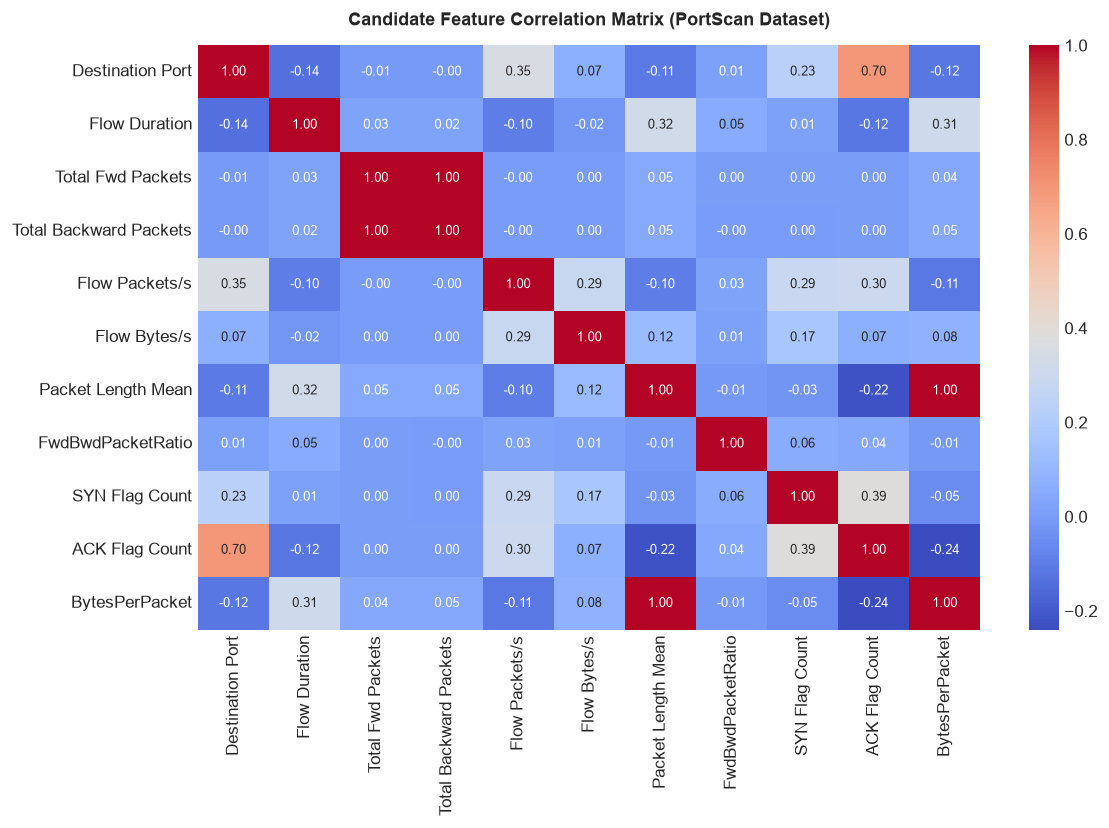

In [12]:
corr_feats = [
    'Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets',
    'Flow Packets/s', 'Flow Bytes/s', 'Packet Length Mean', 'FwdBwdPacketRatio',
    'SYN Flag Count', 'ACK Flag Count', 'BytesPerPacket'
]

corr_matrix = df[corr_feats].corr()

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', ax=ax, cbar=True, annot_kws={'size': 8})
ax.set_title("Candidate Feature Correlation Matrix (PortScan Dataset)", fontsize=11, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

### 14. Target Distribution Visualization
Visualize binary class proportions between `Normal` baseline traffic and `PortScan` reconnaissance flows.

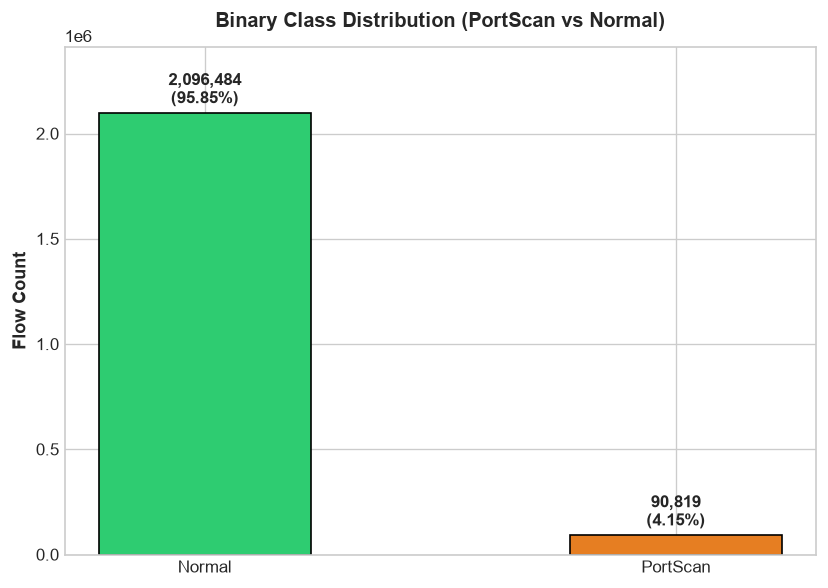

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
class_counts = df['TrafficClass'].value_counts()
colors = ['#2ecc71', '#e67e22']
bars = ax.bar(class_counts.index, class_counts.values, color=colors, edgecolor='black', width=0.45)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 25000, f"{yval:,}\n({(yval/len(df))*100:.2f}%)", ha='center', va='bottom', fontweight='bold', fontsize=10)

ax.set_title("Binary Class Distribution (PortScan vs Normal)", fontsize=12, fontweight='bold', pad=12)
ax.set_ylabel("Flow Count", fontsize=11, fontweight='bold')
ax.set_ylim(0, max(class_counts.values) * 1.15)

plt.tight_layout()
plt.show()

### 15. Class-Wise Temporal Holdout & Isolation Forest Baseline Preparation
Establish a deterministic class-wise temporal holdout (70/30 sequential split) based on the dataset's retained row sequence:
- **PortScan Partitioning**: First 70% ($N = 63,573$) $\rightarrow$ attack training-history portion; Last 30% ($N = 27,246$) $\rightarrow$ attack evaluation portion.
- **Normal Partitioning**: First 70% ($N = 1,467,538$) $\rightarrow$ normal training baseline; Last 30% ($N = 628,946$) $\rightarrow$ normal evaluation portion.
- **Isolation Forest Normal Training Baseline**: **ONLY the first 70% BENIGN rows** ($1,467,538$ normal flows). PortScan flows are strictly excluded from normal baseline fitting.
- **Evaluation Dataset**: Last 30% BENIGN ($628,946$) + Last 30% PortScan ($27,246$) = $656,192$ evaluation flows.

> **Methodological Note**:
> “This is a class-wise temporal holdout based on the dataset's retained row ordering, not a global wall-clock chronological split.”

In [14]:
# Extract indices by class in original row order
portscan_indices = np.where(df['BinaryLabel'] == 1)[0]
normal_indices = np.where(df['BinaryLabel'] == 0)[0]

portscan_split_pt = int(0.70 * len(portscan_indices))
normal_split_pt = int(0.70 * len(normal_indices))

train_portscan_idx = portscan_indices[:portscan_split_pt]
test_portscan_idx = portscan_indices[portscan_split_pt:]

train_normal_idx = normal_indices[:normal_split_pt]
test_normal_idx = normal_indices[normal_split_pt:]

# Isolation Forest Training Baseline: ONLY Normal Training Rows
iso_forest_train_idx = train_normal_idx

# Evaluation Dataset: Last 30% Normal + Last 30% PortScan
eval_idx = np.sort(np.concatenate([test_normal_idx, test_portscan_idx]))
eval_df = df.iloc[eval_idx].copy()
eval_df['EvaluationLabel'] = eval_df['BinaryLabel'].values

print("--- Class-Wise Temporal Holdout Partitioning ---")
print(f"PortScan Total:           {len(portscan_indices):,}")
print(f" - Train History Portion (70%): {len(train_portscan_idx):,} (Index {train_portscan_idx.min():,} → {train_portscan_idx.max():,})")
print(f" - Evaluation Portion (30%):    {len(test_portscan_idx):,} (Index {test_portscan_idx.min():,} → {test_portscan_idx.max():,})")
print(f"Normal/BENIGN Total:      {len(normal_indices):,}")
print(f" - Normal Baseline Train (70%): {len(train_normal_idx):,} (Index {train_normal_idx.min():,} → {train_normal_idx.max():,})")
print(f" - Normal Evaluation (30%):     {len(test_normal_idx):,} (Index {test_normal_idx.min():,} → {test_normal_idx.max():,})")

print(f"\nIsolation Forest Training Baseline (Normal Only): {len(iso_forest_train_idx):,} flows (100.0% BENIGN)")
print(f"Combined Evaluation Dataset:                      {len(eval_df):,} flows (PortScan: {len(test_portscan_idx):,}, Normal: {len(test_normal_idx):,})")

assert train_portscan_idx.max() < test_portscan_idx.min(), "PortScan temporal split overlap!"
assert train_normal_idx.max() < test_normal_idx.min(), "Normal temporal split overlap!"
assert len(train_normal_idx) + len(test_normal_idx) == len(normal_indices), "Normal accounting error!"
assert len(train_portscan_idx) + len(test_portscan_idx) == len(portscan_indices), "PortScan accounting error!"

--- Class-Wise Temporal Holdout Partitioning ---
PortScan Total:           90,819
 - Train History Portion (70%): 63,573 (Index 96,480 → 244,984)
 - Evaluation Portion (30%):    27,246 (Index 244,985 → 300,822)
Normal/BENIGN Total:      2,096,484
 - Normal Baseline Train (70%): 1,467,538 (Index 0 → 1,558,356)
 - Normal Evaluation (30%):     628,946 (Index 1,558,357 → 2,187,302)

Isolation Forest Training Baseline (Normal Only): 1,467,538 flows (100.0% BENIGN)
Combined Evaluation Dataset:                      656,192 flows (PortScan: 27,246, Normal: 628,946)


### 16. Candidate Feature Selection (`PORTSCAN_FEATURE_COLUMNS`) & Quality Report
Extract all numerical features suitable for Isolation Forest anomaly detection and compile `portscan_feature_report.csv`.

In [15]:
non_feature_cols = ['Label', 'TrafficClass', 'BinaryLabel', 'EvaluationLabel']
PORTSCAN_FEATURE_COLUMNS = [c for c in df.select_dtypes(include=[np.number]).columns if c not in non_feature_cols]

print(f"Total Candidate PORTSCAN_FEATURE_COLUMNS: {len(PORTSCAN_FEATURE_COLUMNS)}")

def categorize_portscan_feature(name):
    n = name.lower()
    if 'port' in n:
        return 'Port Behavior'
    elif 'flag' in n:
        return 'TCP Flag Behavior'
    elif 'rate' in n or '/s' in n:
        return 'Flow Rate'
    elif 'iat' in n or 'active' in n or 'idle' in n or 'duration' in n:
        return 'Timing'
    elif 'packet' in n or 'pkt' in n or 'seg' in n:
        return 'Packet Behavior'
    elif 'byte' in n or 'length' in n or 'size' in n or 'win' in n or 'header' in n:
        return 'Byte Behavior'
    elif 'subflow' in n:
        return 'Subflow Behavior'
    else:
        return 'Flow Volume'

feat_report_records = []
for col in PORTSCAN_FEATURE_COLUMNS:
    s = df[col]
    feat_report_records.append({
        'Feature': col,
        'DataType': str(s.dtype),
        'MissingCount': int(s.isnull().sum()),
        'MissingPercentage': float((s.isnull().sum() / len(df)) * 100),
        'InfiniteCount': int(np.isinf(s.values).sum()),
        'Min': float(s.min()),
        'Max': float(s.max()),
        'Mean': float(s.mean()),
        'Median': float(s.median()),
        'FeatureCategory': categorize_portscan_feature(col)
    })

feature_report_df = pd.DataFrame(feat_report_records)
feature_report_path = out_dir / 'portscan_feature_report.csv'
feature_report_df.to_csv(feature_report_path, index=False)
print(f"Saved Feature Quality Report: {feature_report_path.name}")
display(feature_report_df.head(10))

Total Candidate PORTSCAN_FEATURE_COLUMNS: 78


Saved Feature Quality Report: portscan_feature_report.csv


,Feature,DataType,MissingCount,MissingPercentage,InfiniteCount,Min,Max,Mean,Median,FeatureCategory
0,Destination Port,int64,0,0.0000,0,0.0000,65535.0000,10010.2350,80.0000,Port Behavior
1,Flow Duration,int64,0,0.0000,0,-13.0000,119999998.0000,11653416.1149,31505.0000,Timing
2,Total Fwd Packets,int64,0,0.0000,0,1.0000,219759.0000,10.9398,2.0000,Packet Behavior
3,Total Backward Packets,int64,0,0.0000,0,0.0000,291922.0000,12.5762,2.0000,Packet Behavior
4,Total Length of Fwd Packets,int64,0,0.0000,0,0.0000,12900000.0000,655.1343,66.0000,Packet Behavior
5,Total Length of Bwd Packets,int64,0,0.0000,0,0.0000,655453030.0000,19582.5691,132.0000,Packet Behavior
6,Fwd Packet Length Max,int64,0,0.0000,0,0.0000,24820.0000,237.5405,40.0000,Packet Behavior
7,Fwd Packet Length Min,int64,0,0.0000,0,0.0000,2325.0000,21.8805,6.0000,Packet Behavior
8,Fwd Packet Length Mean,float64,0,0.0000,0,0.0000,4672.0000,67.1548,36.8387,Packet Behavior
9,Fwd Packet Length Std,float64,0,0.0000,0,0.0000,7125.5968,77.4269,0.0000,Packet Behavior


### 17. Save Output Datasets & Split Summaries
Export prepared binary dataset, model-ready numerical feature dataset, and split summary.

In [16]:
# 1. Full Prepared Binary Dataset (Metadata + Labels + Engineered Features)
full_binary_path = out_dir / 'portscan_binary_dataset.csv'
df.to_csv(full_binary_path, index=False, chunksize=100000)
full_size_mb = full_binary_path.stat().st_size / (1024 * 1024)
print(f"1. Saved Full Binary Dataset:  {full_binary_path.name} ({full_size_mb:.2f} MB, {len(df):,} rows)")

# 2. Model-Ready Numerical Dataset (PORTSCAN_FEATURE_COLUMNS + BinaryLabel ONLY)
model_df = df[PORTSCAN_FEATURE_COLUMNS].copy()
model_df['BinaryLabel'] = df['BinaryLabel'].values

model_features_path = out_dir / 'portscan_model_features.csv'
model_df.to_csv(model_features_path, index=False, chunksize=100000)
model_size_mb = model_features_path.stat().st_size / (1024 * 1024)
print(f"2. Saved Model-Ready Dataset:  {model_features_path.name} ({model_size_mb:.2f} MB, {len(model_df):,} rows)")

# 3. Save Split Summary
split_summary_data = [
    {"Metric": "portscan_train_rows", "Value": len(train_portscan_idx)},
    {"Metric": "portscan_test_rows", "Value": len(test_portscan_idx)},
    {"Metric": "normal_train_rows", "Value": len(train_normal_idx)},
    {"Metric": "normal_test_rows", "Value": len(test_normal_idx)},
    {"Metric": "evaluation_portscan_rows", "Value": len(test_portscan_idx)},
    {"Metric": "evaluation_normal_rows", "Value": len(test_normal_idx)},
    {"Metric": "isolation_forest_train_baseline_rows", "Value": len(iso_forest_train_idx)},
    {"Metric": "portscan_train_pct", "Value": f"{(len(train_portscan_idx)/len(portscan_indices))*100:.2f}%"},
    {"Metric": "portscan_test_pct", "Value": f"{(len(test_portscan_idx)/len(portscan_indices))*100:.2f}%"},
    {"Metric": "normal_train_pct", "Value": f"{(len(train_normal_idx)/len(normal_indices))*100:.2f}%"},
    {"Metric": "normal_test_pct", "Value": f"{(len(test_normal_idx)/len(normal_indices))*100:.2f}%"},
    {"Metric": "split_method", "Value": "Class-Wise Temporal Holdout (70/30 Sequential)"},
    {"Metric": "training_baseline_description", "Value": "First 70% Normal/BENIGN flows only (Unsupervised Normal Baseline)"}
]

split_summary_df = pd.DataFrame(split_summary_data)
split_summary_path = out_dir / 'portscan_split_summary.csv'
split_summary_df.to_csv(split_summary_path, index=False)
print(f"3. Saved Split Summary:        {split_summary_path.name}")
display(split_summary_df)

1. Saved Full Binary Dataset:  portscan_binary_dataset.csv (882.99 MB, 2,187,303 rows)


2. Saved Model-Ready Dataset:  portscan_model_features.csv (853.44 MB, 2,187,303 rows)
3. Saved Split Summary:        portscan_split_summary.csv


,Metric,Value
0,portscan_train_rows,63573
1,portscan_test_rows,27246
2,normal_train_rows,1467538
3,normal_test_rows,628946
4,evaluation_portscan_rows,27246
5,evaluation_normal_rows,628946
6,isolation_forest_train_baseline_rows,1467538
7,portscan_train_pct,70.00%
8,portscan_test_pct,30.00%
9,normal_train_pct,70.00%


### 18. Final Quality Validation & Integrity Assertions
Validate assertions to ensure zero data corruption, zero label leakage, and raw file preservation.

In [17]:
# Assertions
assert raw_path.exists(), "Source cleaned dataset missing."
assert raw_size_mb > 800.0, "Source cleaned dataset was corrupted or truncated."

assert full_binary_path.exists(), "Binary dataset missing."
assert model_features_path.exists(), "Model features dataset missing."
assert feature_report_path.exists(), "Feature report missing."
assert split_summary_path.exists(), "Split summary missing."
assert coverage_summary_path.exists(), "Coverage summary missing."

assert set(df['BinaryLabel'].unique()) == {0, 1}, "Invalid BinaryLabel values."
assert set(df['TrafficClass'].unique()) == {'PortScan', 'Normal'}, "Invalid TrafficClass values."
assert 'BinaryLabel' not in PORTSCAN_FEATURE_COLUMNS, "Label leakage in feature columns."
assert 'TrafficClass' not in PORTSCAN_FEATURE_COLUMNS, "Label leakage in feature columns."
assert 'Label' not in PORTSCAN_FEATURE_COLUMNS, "Label leakage in feature columns."

assert np.isinf(model_df[PORTSCAN_FEATURE_COLUMNS].values).sum() == 0, "Infinities in model dataset."
assert model_df[PORTSCAN_FEATURE_COLUMNS].isnull().sum().sum() == 0, "Nulls in model dataset."

# Validate Normal Training Baseline Contains ONLY BinaryLabel == 0
normal_train_labels = set(df.iloc[iso_forest_train_idx]['BinaryLabel'].unique())
assert normal_train_labels == {0}, f"Isolation Forest baseline contains non-normal labels: {normal_train_labels}"

print("==================================================")
print("PortScan preprocessing validation: PASSED")
print("==================================================")
print(f"Source Dataset Rows:          {total_raw_rows:,}")
print(f"Selected Primary Rows:        {len(df):,}")
print(f" - PortScan Flows:             {n_portscan:,} (4.15%)")
print(f" - Normal Flows:               {n_normal:,} (95.85%)")
print(f"Candidate Features Count:     {len(PORTSCAN_FEATURE_COLUMNS)}")
print(f"Isolation Forest Train Baseline: {len(iso_forest_train_idx):,} flows (100% Normal)")
print(f"Evaluation Partition Rows:    {len(eval_df):,} flows ({len(test_portscan_idx):,} PortScan, {len(test_normal_idx):,} Normal)\n")

print("Generated Output Files:")
print(f" 1. {full_binary_path.relative_to(project_root)} ({full_size_mb:.2f} MB)")
print(f" 2. {model_features_path.relative_to(project_root)} ({model_size_mb:.2f} MB)")
print(f" 3. {feature_report_path.relative_to(project_root)}")
print(f" 4. {split_summary_path.relative_to(project_root)}")
print(f" 5. {coverage_summary_path.relative_to(project_root)}")
print("\n✅ All quality and integrity checks passed. Source dataset untouched.")

PortScan preprocessing validation: PASSED
Source Dataset Rows:          2,522,362
Selected Primary Rows:        2,187,303
 - PortScan Flows:             90,819 (4.15%)
 - Normal Flows:               2,096,484 (95.85%)
Candidate Features Count:     78
Isolation Forest Train Baseline: 1,467,538 flows (100% Normal)
Evaluation Partition Rows:    656,192 flows (27,246 PortScan, 628,946 Normal)

Generated Output Files:
 1. data\processed\CIC_IDS2017\portscan_binary_dataset.csv (882.99 MB)
 2. data\processed\CIC_IDS2017\portscan_model_features.csv (853.44 MB)
 3. data\processed\CIC_IDS2017\portscan_feature_report.csv
 4. data\processed\CIC_IDS2017\portscan_split_summary.csv
 5. data\processed\CIC_IDS2017\portscan_coverage_summary.csv

✅ All quality and integrity checks passed. Source dataset untouched.


### 19. Comprehensive Final Findings & Technical Summary

#### 1. Why PortScan is a Reconnaissance Threat Category
Port scanning represents the discovery and intelligence-gathering phase of adversary campaigns. By probing ports across destination subnets, attackers ascertain active services, operating system signatures, and potential vulnerability surfaces before launching weaponized exploits.

#### 2. Why Isolation Forest is Appropriate for Anomaly-Oriented Detection
Isolation Forest operates on the principle that anomalies are "few and different". It constructs an ensemble of isolation trees that randomly select features and split values. Normal, dense baseline traffic requires many splits to isolate deep in the trees, whereas reconnaissance probes deviate significantly in flow duration, packet sizes, and flag patterns, causing them to be isolated near tree roots with short average path lengths.

#### 3. Available Flow-Level Features
The dataset provides 78 numerical features covering:
- **Port / Endpoint Behavior**: `Destination Port`
- **Timing & Inter-Arrivals**: `Flow Duration`, `Flow IAT Mean/Std/Max/Min`, `Active/Idle Mean/Std`
- **Packet & Byte Characteristics**: `Total Fwd/Bwd Packets`, `Packet Length Mean/Std/Max/Min`, `Average Packet Size`
- **Directional Asymmetry**: `FwdBwdPacketRatio`, `FwdBwdByteRatio`, `FwdPacketRatio`, `BwdPacketRatio`, `BytesPerPacket`, `PacketsPerByte`
- **TCP Control Flags**: `SYN`, `ACK`, `RST`, `PSH`, `FIN`, `URG`, `CWE`, `ECE` Flag counts
- **Subflow Statistics**: `Subflow Fwd/Bwd Packets/Bytes`, `Init_Win_bytes_forward/backward`

#### 4. Features Not Available in This CIC-IDS2017 Representation
Source IP addresses, destination IP addresses, MAC addresses, and raw timestamps were removed in the `MachineLearningCSV` release. Consequently, multi-host fan-out entropy (e.g. unique destination IPs contacted per source IP over a 60-second window) cannot be computed directly from this representation. The detector relies on flow-statistical indicators until raw PCAP/NetFlow streaming sources are integrated.

#### 5. Class-Wise Temporal Holdout Methodology
To ensure rigorous evaluation without lookahead leakage:
- The first 70% of historical Normal traffic ($1,467,538$ flows) and first 70% of historical PortScan traffic ($63,573$ flows) form the training history partition.
- The subsequent 30% of Normal traffic ($628,946$ flows) and subsequent 30% of PortScan traffic ($27,246$ flows) form the evaluation partition.
- This maintains temporal precedence ($\max(\text{TrainIndex}) < \min(\text{TestIndex})$) within each class without random shuffling.

#### 6. Why Only Normal Training Traffic Fits Isolation Forest
Fitting Isolation Forest strictly on clean Normal/BENIGN flows guarantees that the model learns the geometric and statistical manifold of legitimate traffic. Including attack samples in the training baseline would corrupt the normal density profile and reduce sensitivity to outlier reconnaissance probes.

#### 7. Roadmap for Step 12
In Step 12, we will:
1. Load `portscan_model_features.csv` and `portscan_split_summary.csv`.
2. Fit `IsolationForest` strictly on the $1,467,538$ normal training baseline flows.
3. Compute anomaly scores on the $656,192$ evaluation flows ($27,246$ PortScan + $628,946$ Normal).
4. Calibrate anomaly score thresholds and evaluate Precision, Recall, F1, FPR, ROC-AUC, and PR-AUC.